In [1]:
import pandas as pd
import matplotlib.pyplot as plt

import metpy.calc as mpcalc
from metpy.cbook import get_test_data

from metpy.units import units
import numpy as np
import csv
import os
from netCDF4 import Dataset

from wrf import (getvar, interplevel, vertcross,
                 CoordPair, ALL_TIMES, to_np,ll_to_xy,
                 get_cartopy, latlon_coords,
                 cartopy_xlim, cartopy_ylim,smooth2d, extract_times)

/glade/work/fdemartin/conda-envs/jupyter/lib/python3.11/site-packages/pyproj/network.py:59: UserWarning: pyproj unable to set PROJ database path.
  _set_context_ca_bundle_path(ca_bundle_path)


In [2]:
def write_wrfprof(p_2m, z, pot_tmp, r, u, v, f_out):
    # surface measurements
    t_2m = pot_tmp[0]  # surface potential Temperature
    r_2m = r[0]  # surface vapor mixing ratio
    n_levels = z.shape[0]

    line1 = '{:9.2f} {:9.2f} {:10.2f}'.format(p_2m, t_2m, r_2m)
    wrfformat = '{:9.2f} {:9.2f} {:10.2f} {:10.2f} {:10.2f}'

    with open(f_out, 'w') as f:
        f.write(line1+' \n')
        for i in range(n_levels-1):  # ignore last level due to nan
            d = wrfformat.format(z[i], pot_tmp[i], r[i], u[i], v[i])
            #print(d)
            f.write(d+ '\n')
    print(f_out, 'saved.')

def extract_time(filename):
    import re
    match = re.search(r'(\d{2}):(\d{2})', filename)
    if match:
        time=int(match.group(1))*60+ int(match.group(2))
        #print(time,int(match.group(1)), int(match.group(2)))
        #return time  # (hh, mm)
        return int(match.group(1)), int(match.group(2))  # (hh, mm)
    return (99,99)  # Un valore alto per file senza orario


In [10]:
dir="/glade/derecho/scratch/fdemartin/ens/"
folder="no_urban"
#folder="no_urban"
#WRF_DIRECTORY=dir+folder+"/wrfout_d01_2023-05-31_00:00:00"
WRF_DIRECTORY=dir+folder+"/0/wrfout_d01_2023-05-31_15:30:00"
ncfile = Dataset(WRF_DIRECTORY)

times = getvar(ncfile,'times',timeidx=ALL_TIMES, meta=False)

period=len(times)
period=(18-8)*6+1
start_time=8
delta_time=1/6
sounding_hour=14
#st=int((sounding_hour-start_time)/delta_time)
st=36
# #print(st)

# x_u=85 #urban point
# y_u=75

# x_r=130 #rural point
# y_r=75

# x_s=x_r #sounding point
# y_s=y_r

# #print(start_time+delta_time*(period)
time_wrf1=(np.linspace(start_time,start_time+delta_time*(period-1),period)+2)*units.hour

# #print(time_wrf1)

# t_point1=np.zeros([period])
# td_point1=np.zeros([period])

exp=folder
#folder=exp
#member='10'
#WRF_DIRECTORY="/glade/derecho/scratch/fdemartin/ens/"+exp+"/"+member+"/"
WRF_DIRECTORY="/glade/derecho/scratch/fdemartin/ens/"+exp+"/0/"

#RF_DIRECTORY=dir+"1_wrfout_d01_2023-05-31_08:00:00"
os.chdir(WRF_DIRECTORY)
WRF_FILES = os.listdir()

_WRF_FILES = [os.path.abspath(os.path.expanduser(
    os.path.join(WRF_DIRECTORY, f))) for f in WRF_FILES]

def single_wrf_file():
    global _WRF_FILES
    return _WRF_FILES[0]

def multiple_wrf_files():
    global _WRF_FILES
    return _WRF_FILES

file_paths = multiple_wrf_files() # Necessary due to single_wrf_file being a function
#print(file_paths)
file_paths = sorted(file_paths, key=extract_time)

ncfile = [Dataset(f) for f in file_paths]
period=len(WRF_FILES)
#print(nc_files)
#ncfile = Dataset(WRF_DIRECTORY)
#times = to_np(getvar(wrf_files,'times',timeidx=ALL_TIMES, meta=False,method="cat"))
#print(times)
#time_wrf1=np.linspace(start_time,start_time+delta_time*(period-1),period)*units.hour

#p_join = getvar(wrflist, "P", timeidx=ALL_TIMES, method="join")

# T=to_np(getvar(wrf_files,"T2",timeidx=ALL_TIMES,method="cat"))
# Q=to_np(getvar(wrf_files,"Q2",timeidx=ALL_TIMES,method="cat"))
# wa=to_np(getvar(wrf_files,"T2",timeidx=ALL_TIMES,method="cat"))
# p=to_np(getvar(wrf_files,"pressure",timeidx=ALL_TIMES,method="cat"))
# var_lu=to_np(getvar(wrf_files,"LU_INDEX",timeidx=ALL_TIMES,method="cat"))

In [11]:
#for i in range (0,period):
# raggio attorno al quale calcolare la media
x_u=85 #urban point #85
y_u=75 #75

x_r=150 #rural point #130
y_r=75 #75

x_s=x_r #sounding point
y_s=y_r

radius = 1

T=to_np(getvar(ncfile,'T2',timeidx=ALL_TIMES,method='cat'))#[:,y_u,x_u])
Q=to_np(getvar(ncfile, 'Q2',timeidx=ALL_TIMES,method='cat'))#[:,y_u,x_u])
T_r=to_np(getvar(ncfile,'T2',timeidx=ALL_TIMES,method='cat'))#[:,y_r,x_r])
Q_r=to_np(getvar(ncfile, 'Q2',timeidx=ALL_TIMES,method='cat'))#[:,y_r,x_r])

subarray = to_np(getvar(ncfile, 'p', timeidx=st,method='cat')[:,y_r-radius:y_r+radius,x_r-radius:x_r+radius])
print(np.shape(subarray))
pressure=np.mean(subarray,axis=(1,2))
subarray = to_np(getvar(ncfile, 'T', timeidx=st)[:,y_r-radius:y_r+radius,x_r-radius:x_r+radius])+300
theta=np.mean(subarray,axis=(1,2))
tc=(mpcalc.temperature_from_potential_temperature(units.Quantity(pressure,'Pa'),units.Quantity(theta,'K')).to('degC')).m
subarray = to_np(getvar(ncfile, 'QVAPOR', timeidx=st)[:,y_r-radius:y_r+radius,x_r-radius:x_r+radius])
q=np.mean(subarray,axis=(1,2))
td=(mpcalc.dewpoint_from_specific_humidity(units.Quantity(pressure,'Pa'),units.Quantity(tc,'degC'),units.Quantity(q,'kg/kg')).to('degC')).m
subarray = to_np(getvar(ncfile, 'ua', timeidx=st)[:,y_r-radius:y_r+radius,x_r-radius:x_r+radius])
ua=np.mean(subarray,axis=(1,2))
subarray = to_np(getvar(ncfile, 'va', timeidx=st)[:,y_r-radius:y_r+radius,x_r-radius:x_r+radius])
va=np.mean(subarray,axis=(1,2))
subarray = to_np(getvar(ncfile, 'height', timeidx=st)[:,y_r-radius:y_r+radius,x_r-radius:x_r+radius])
z=np.mean(subarray,axis=(1,2))

subarray = to_np(getvar(ncfile, 'p', timeidx=st)[:,y_u-radius:y_u+radius,x_u-radius:x_u+radius])
pressureu=np.mean(subarray,axis=(1,2))
subarray = to_np(getvar(ncfile, 'T', timeidx=st)[:,y_u-radius:y_u+radius,x_u-radius:x_u+radius])+300
theta=np.mean(subarray,axis=(1,2))
tcu=(mpcalc.temperature_from_potential_temperature(units.Quantity(pressure,'Pa'),units.Quantity(theta,'K')).to('degC')).m
subarray = to_np(getvar(ncfile, 'QVAPOR', timeidx=st)[:,y_u-radius:y_u+radius,x_u-radius:x_u+radius])
q=np.mean(subarray,axis=(1,2))
tdu=(mpcalc.dewpoint_from_specific_humidity(units.Quantity(pressure,'Pa'),units.Quantity(tc,'degC'),units.Quantity(q,'kg/kg')).to('degC')).m
subarray = to_np(getvar(ncfile, 'ua', timeidx=st)[:,y_u-radius:y_u+radius,x_u-radius:x_u+radius])
uau=np.mean(subarray,axis=(1,2))
subarray = to_np(getvar(ncfile, 'va', timeidx=st)[:,y_u-radius:y_u+radius,x_u-radius:x_u+radius])
vau=np.mean(subarray,axis=(1,2))
subarray = to_np(getvar(ncfile, 'height', timeidx=st)[:,y_u-radius:y_u+radius,x_u-radius:x_u+radius])
zu=np.mean(subarray,axis=(1,2))

(63, 2, 2)


In [12]:
# raggio attorno al quale calcolare la media
radius = 2

# Seleziona l'intorno
subarray = T_r[:,y_u-radius:y_u+radius+1, x_u-radius:x_u+radius+1]
print(np.shape(subarray))
T2m = np.mean(subarray,axis=(1,2))
subarray = T_r[:,y_r-radius:y_r+radius+1, x_r-radius:x_r+radius+1]
print(np.shape(subarray))
T2_rm = np.mean(subarray,axis=(1,2))
subarray = Q_r[:,y_u-radius:y_u+radius+1, x_u-radius:x_u+radius+1]
Qm = np.mean(subarray,axis=(1,2))
subarray = Q_r[:,y_r-radius:y_r+radius+1, x_r-radius:x_r+radius+1]
Q_rm = np.mean(subarray,axis=(1,2))

(61, 5, 5)
(61, 5, 5)


In [13]:
#folder="no_urban_no_bubble_specialcity"
data=np.vstack([T2m,Qm,T2_rm,Q_rm])
data_t=np.transpose(data)
df=pd.DataFrame(data_t,index=time_wrf1, columns=['T2_u','Q2_u','T2_r','Q2_r'])
df.to_csv("/glade/u/home/fdemartin/dati/derecho/punti_"+folder+".csv")

data=np.vstack([z,pressure,tc,td,ua,va])
data_t=np.transpose(data)
df=pd.DataFrame(data_t,index=z, columns=['z','p','t','td','ua','va'])
df.to_csv("/glade/u/home/fdemartin/dati/derecho/metpy_sounding_rural_1530_"+folder+".csv")

data=np.vstack([zu,pressureu,tcu,tdu,uau,vau])
data_t=np.transpose(data)
df=pd.DataFrame(data_t,index=z, columns=['z','p','t','td','ua','va'])
df.to_csv("/glade/u/home/fdemartin/dati/derecho/metpy_sounding_urban_1530_"+folder+".csv")

f_out = '/glade/u/home/fdemartin/dati/derecho/input_sounding'
p_2m = pressure[0]  # surface pressure
write_wrfprof(p_2m/100, z, theta, q*1000, ua, va, f_out)

/glade/u/home/fdemartin/dati/derecho/input_sounding saved.


In [69]:
print("finished")

finished


/glade/work/fdemartin/conda-envs/jupyter/lib/python3.11/site-packages/metpy/calc/thermo.py:1403: RuntimeWarning: invalid value encountered in log
  val = np.log(vapor_pressure / mpconsts.nounit.sat_pressure_0c)


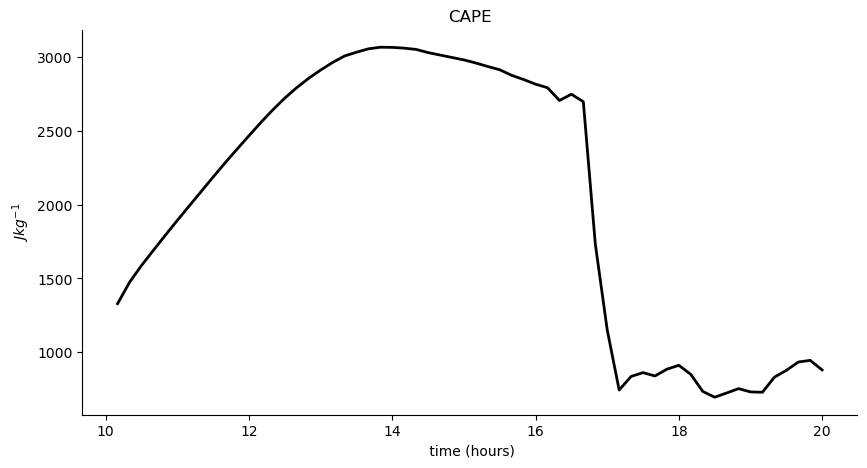

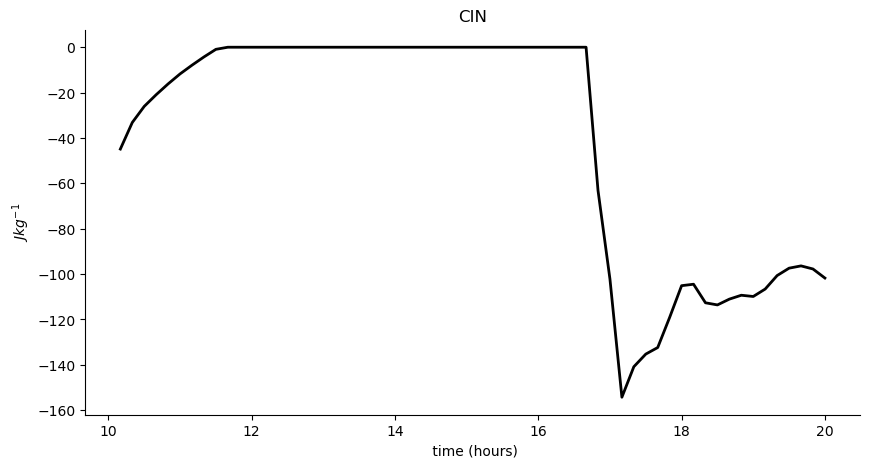

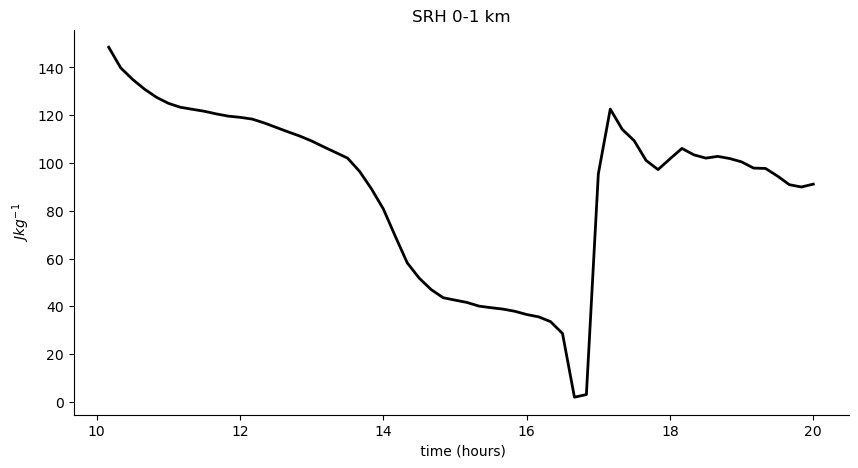

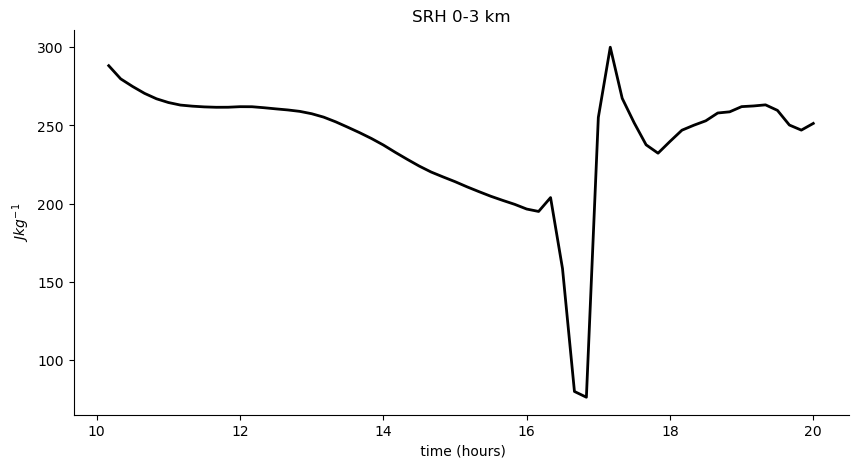

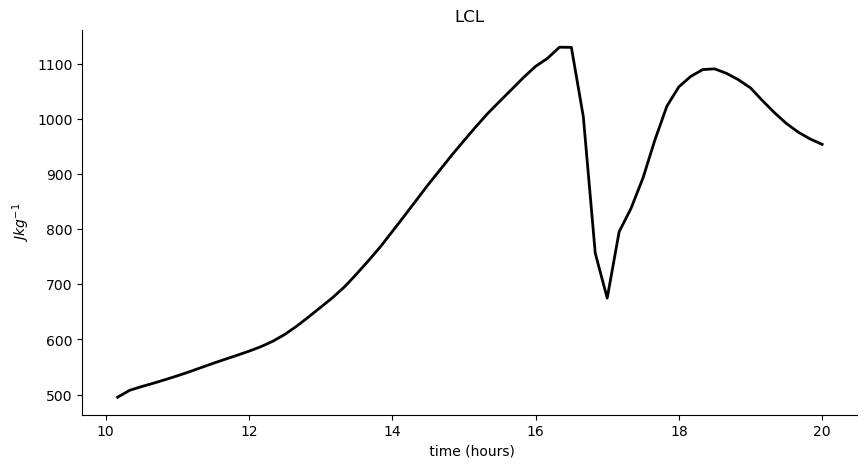

In [22]:
pressure = to_np(getvar(ncfile, 'p', timeidx=ALL_TIMES))
#print(pressure)
theta = to_np(getvar(ncfile, 'T', timeidx=ALL_TIMES))+300
tc=(mpcalc.temperature_from_potential_temperature(units.Quantity(pressure,'Pa'),units.Quantity(theta,'K')).to('degC')).m
q = to_np(getvar(ncfile, 'QVAPOR', timeidx=ALL_TIMES))
td=(mpcalc.dewpoint_from_specific_humidity(units.Quantity(pressure,'Pa'),units.Quantity(tc,'degC'),units.Quantity(q,'kg/kg')).to('degC')).m
ua = to_np(getvar(ncfile, 'ua', timeidx=ALL_TIMES))
va = to_np(getvar(ncfile, 'va', timeidx=ALL_TIMES))
z = to_np(getvar(ncfile, 'height', timeidx=ALL_TIMES))

# raggio attorno al quale calcolare la media quando voglio calcolare la media su tutto il dominio
# radius = 80

# Seleziona l'intorno

subarray = pressure[:,:,y_u-radius:y_u+radius+1, x_u-radius:x_u+radius+1]
#print(y_u-radius,x_u-radius)
pressure = np.mean(subarray,axis=(2,3))
subarray = tc[:,:,y_u-radius:y_u+radius+1, x_u-radius:x_u+radius+1]
tc = np.mean(subarray,axis=(2,3))
subarray = td[:,:,y_u-radius:y_u+radius+1, x_u-radius:x_u+radius+1]
td = np.mean(subarray,axis=(2,3))
subarray = ua[:,:,y_u-radius:y_u+radius+1, x_u-radius:x_u+radius+1]
ua = np.mean(subarray,axis=(2,3))
subarray = va[:,:,y_u-radius:y_u+radius+1, x_u-radius:x_u+radius+1]
va = np.mean(subarray,axis=(2,3))
subarray = z[:,:,y_u-radius:y_u+radius+1, x_u-radius:x_u+radius+1]
z = np.mean(subarray,axis=(2,3))

#print(pressure)
u=units.Quantity(ua,"m/s")
v=units.Quantity(va,"m/s")
hght=units.Quantity(z,"m")
t=units.Quantity(tc,"degC")
dp=units.Quantity(td,"degC")
p=units.Quantity(pressure,"Pa")

cape=np.zeros(period)
cin=np.zeros(period)
srh=np.zeros(period)
srh1=np.zeros(period)
lcl=np.zeros(period)

for i in range(0,period):
    capet, cint = mpcalc.surface_based_cape_cin(p[i,:], t[i,:], dp[i,:])#, parcel_prof)
    cape[i] = capet.magnitude
    cin[i] = cint.magnitude
    lclpres, lcltemp = mpcalc.lcl(p[i,0], t[i,0], dp[i,0])
    right_mover, left_mover, wind_mean=mpcalc.bunkers_storm_motion(p[i,:], u[i,:], v[i,:], hght[i,:])
    u_storm=right_mover[0]
    v_storm=right_mover[1]
    psrh, nsrh, srht = mpcalc.storm_relative_helicity(hght[i,:], u[i,:], v[i,:], 3000*units.m, bottom=0*units.m, storm_u=u_storm, storm_v=v_storm)
    psrh1, nsrh1, srh1t = mpcalc.storm_relative_helicity(hght[i,:],u[i,:], v[i,:], 1000*units.m, bottom=0*units.m, storm_u=u_storm, storm_v=v_storm)
    srh[i]=srht.magnitude
    srh1[i]=srh1t.magnitude
    lcl[i] = (np.interp(lclpres.m, p[i,::-1].m, hght[i,::-1])).magnitude

fig,ax1 = plt.subplots(figsize=[10,5],ncols=1,sharey=True)
plt.plot(time_wrf1[1:],cape[1:], 'k-', linewidth=2,label='urban km5')
plt.xlabel(' time (hours)')
plt.tick_params(axis='y')
ax1.set_ylabel('$Jkg^{-1}$')
plt.title('CAPE')
#ax1.set_ylim(0,3500)
#plt.grid()
ax1.spines['top'].set_visible(False)  # Rimuove il bordo superiore
ax1.spines['right'].set_visible(False)  # Rimuove il bordo destro
#plt.legend(loc=3)
#plt.show()
file_name='CAPE.png'
plt.savefig(dir  + file_name, dpi = 130, bbox_inches = 'tight', pad_inches = 0)

fig,ax1 = plt.subplots(figsize=[10,5],ncols=1,sharey=True)
plt.plot(time_wrf1[1:],cin[1:], 'k-', linewidth=2,label='urban km5')
plt.xlabel(' time (hours)')
plt.tick_params(axis='y')
ax1.set_ylabel('$Jkg^{-1}$')
plt.title('CIN')
ax1.spines['top'].set_visible(False)  # Rimuove il bordo superiore
ax1.spines['right'].set_visible(False)  # Rimuove il bordo destro
#ax1.set_ylim(0,3500)
#plt.grid()
#plt.legend(loc=3)
#plt.show()
file_name='CIN.png'

plt.savefig(dir  + file_name, dpi = 130, bbox_inches = 'tight', pad_inches = 0)
fig,ax1 = plt.subplots(figsize=[10,5],ncols=1,sharey=True)
plt.plot(time_wrf1[1:],srh1[1:], 'k-', linewidth=2,label='urban km5')
plt.xlabel(' time (hours)')
plt.tick_params(axis='y')
ax1.set_ylabel('$Jkg^{-1}$')
plt.title('SRH 0-1 km')
ax1.spines['top'].set_visible(False)  # Rimuove il bordo superiore
ax1.spines['right'].set_visible(False)  # Rimuove il bordo destro
#ax1.set_ylim(0,3500)
#plt.grid()
#plt.legend(loc=3)
#plt.show()
file_name='SRH1.png'
plt.savefig(dir + file_name, dpi = 130, bbox_inches = 'tight', pad_inches = 0)

plt.savefig(dir + "_" + file_name, dpi = 130, bbox_inches = 'tight', pad_inches = 0)
fig,ax1 = plt.subplots(figsize=[10,5],ncols=1,sharey=True)
plt.plot(time_wrf1[1:],srh[1:], 'k-', linewidth=2,label='urban km5')
plt.xlabel(' time (hours)')
plt.tick_params(axis='y')
ax1.set_ylabel('$Jkg^{-1}$')
plt.title('SRH 0-3 km')
ax1.spines['top'].set_visible(False)  # Rimuove il bordo superiore
ax1.spines['right'].set_visible(False)  # Rimuove il bordo destro
#ax1.set_ylim(0,3500)
#plt.grid()
#plt.legend(loc=3)
#plt.show()
file_name='SRH.png'
plt.savefig(dir + file_name, dpi = 130, bbox_inches = 'tight', pad_inches = 0)

plt.savefig(dir + "_" + file_name, dpi = 130, bbox_inches = 'tight', pad_inches = 0)
fig,ax1 = plt.subplots(figsize=[10,5],ncols=1,sharey=True)
plt.plot(time_wrf1[1:],lcl[1:], 'k-', linewidth=2,label='urban km5')
plt.xlabel(' time (hours)')
plt.tick_params(axis='y')
ax1.set_ylabel('$Jkg^{-1}$')
ax1.spines['top'].set_visible(False)  # Rimuove il bordo superiore
ax1.spines['right'].set_visible(False)  # Rimuove il bordo destro
plt.title('LCL')
#ax1.set_ylim(0,3500)
#plt.grid()
#plt.legend(loc=3)
#plt.show()
file_name='LCL.png'
plt.savefig(dir + file_name, dpi = 130, bbox_inches = 'tight', pad_inches = 0)